# Bundle Neural Networks

A sheaf predicts maps per *edge*. A **flat vector bundle** is a special, more economical sheaf: every node carries an orthogonal **local frame** $O_v$, and the transport between two neighbours is fixed by their frames, $O_u^{\top}O_v$. **Bundle Neural Networks** (BuNN; Bamberger et al., 2025) exploit this structure. Because the transports factor through the nodes, the bundle heat equation can be solved *exactly*, with the ordinary graph heat kernel in a synchronized frame. A single layer can therefore spread information over any distance, set by a diffusion time $t$. The paper calls this **message diffusion**, as opposed to message passing.

### What You Will Learn
* How flat bundles relate to general sheaves, and why the bundle Laplacian factorizes into *synchronize, diffuse, desynchronize*.
* How the heat kernel $e^{-t\mathcal{L}}$ turns the diffusion time $t$ into a receptive-field knob, and how the repository's Taylor and spectral solvers evaluate it.
* The exact BuNN layer implemented in `src/sheaf_mpnn/bunn/`.
* How to read a trained BuNN: its learned node frames, the relative transports they induce on same- and cross-class edges, and its diffusion times.

### Notebook Roadmap
1. **Motivate** bundles and message diffusion.
2. **Formalize** the flat-bundle Laplacian and verify its factorization numerically.
3. **Explore** the heat kernel: reach, solvers, and truncation.
4. **Train** a BuNN on a heterophilic graph next to NSD.
5. **Interpret** the learned frames and diffusion times.

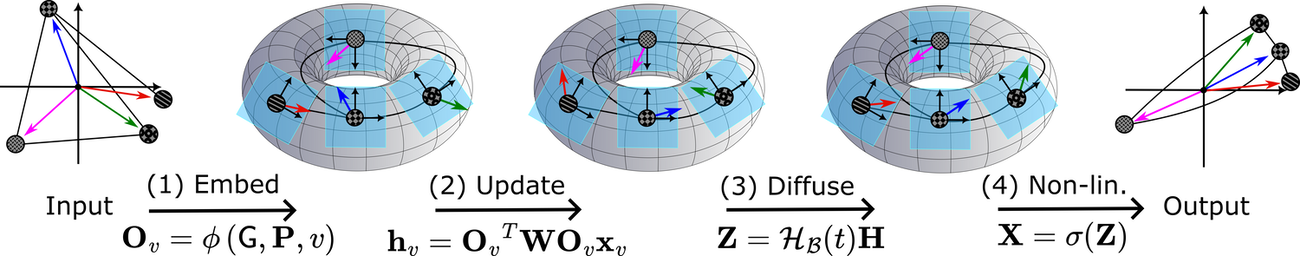

*The message diffusion framework on a 4-node graph: (1) an orthogonal map O_v is computed for each node by embedding the nodes in a manifold with local reference frames (a torus for illustration), (2) features are updated in the synchronized frame, (3) they diffuse with the bundle heat kernel H_B(t), and (4) a nonlinearity is applied.*

<sub>Source: Bamberger et al. (2025), *Bundle Neural Networks for message diffusion on graphs*, [arXiv:2405.15540](https://arxiv.org/abs/2405.15540), Fig. 3. Reproduced for teaching with attribution (CC BY 4.0).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Flat Bundles](#3-flat-bundles)
    * [From Sheaves to Bundles](#sheaves-to-bundles)
    * [Synchronize, Diffuse, Desynchronize](#sync-diffuse)
4. [The Heat Kernel](#4-heat-kernel)
    * [Diffusion Time as a Receptive Field](#diffusion-time)
    * [Taylor and Spectral Solvers](#solvers)
5. [Dataset Pipeline and Models](#5-dataset-and-models)
6. [Training Pipeline](#6-training-pipeline)
7. [Interpreting a Trained BuNN](#7-interpretation)
    * [Learned Node Frames](#learned-frames)
    * [Relative Transports](#relative-transports)
    * [Learned Diffusion Times and Solver Agreement](#diffusion-times)
8. [Configuration, Reproducibility, and Exercises](#8-exercises)

<a id="1-introduction"></a>
# 1. Introduction

Message passing moves information one hop per layer, which is the root of **oversquashing** (notebook 0, Section 12.3). Reaching distant nodes requires many layers, and the signal is compressed at every bottleneck along the way. Diffusion equations offer an alternative. The heat equation $\dot{X} = -\mathcal{L}X$ has the closed-form solution $X(t) = e^{-t\mathcal{L}}X(0)$, and the heat kernel $e^{-t\mathcal{L}}$ couples *every* pair of nodes in a connected component, with a weight that decays with distance at a rate set by $t$.

On a plain graph this is not enough: heat diffusion is the ultimate smoother, and all nodes converge to the same value (oversmoothing). On a **bundle**, nodes keep individual frames. Diffusion averages features only *after* aligning them through the frames, so the limit of diffusion is no longer "all nodes equal" but "all nodes consistent up to their frames". This is a much richer family of signals, able to keep classes apart.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

Use the repository's Python 3.13 environment (`uv sync`) and run the notebook top to bottom from a fresh kernel. Everything runs on CPU in about a minute.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import copy
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Repository-Specific Modules
# =====================================================================
from torch_geometric.utils import homophily, stochastic_blockmodel_graph

from sheaf_mpnn.bunn import BuNNModel
from sheaf_mpnn.bunn.bundle import desync, sync
from sheaf_mpnn.bunn.bunn_layers import stable_taylor_degree
from sheaf_mpnn.nsd import NSDModel, NSDVariant

print("Loaded BuNNModel, its sync/desync operators, and the NSD baseline.")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0
Loaded BuNNModel, its sync/desync operators, and the NSD baseline.


<a id="3-flat-bundles"></a>
# 3. Flat Bundles

<a id="sheaves-to-bundles"></a>
### 3.1 From Sheaves to Bundles

A sheaf with **orthogonal** restriction maps is a discrete vector bundle: the transport across an edge $e = (u, v)$ is the rotation or reflection $\mathcal{F}_{u \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e}$. A bundle is **flat** when transport around every cycle is trivial (no holonomy). Then each node can be given a single frame $O_v \in O(d)$, and every transport is determined by the frames: $O_{uv} = O_u^{\top}O_v$.

Flatness is a real restriction. A general orthogonal sheaf has $\mathcal{O}(|\mathcal{E}|)$ independent maps and can carry holonomy, while a flat bundle has only $|\mathcal{V}|$ frames. In exchange, the bundle Laplacian has a structure that makes its heat kernel easy to compute.

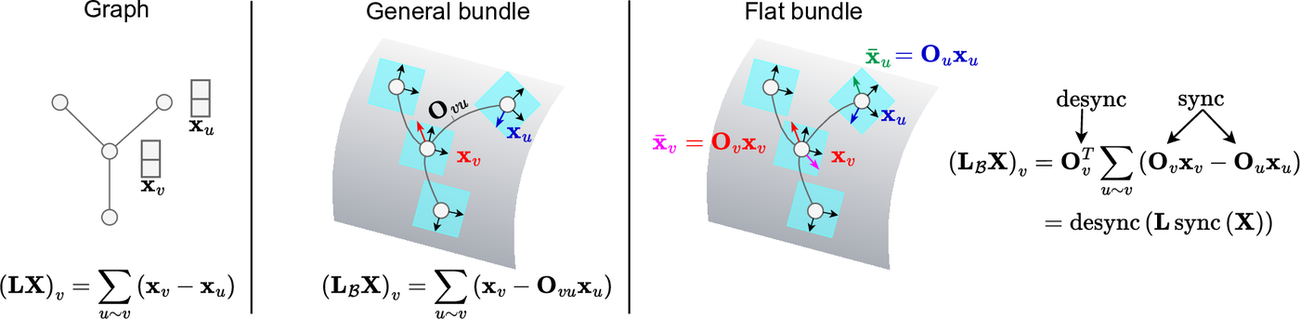

*From left to right: the standard graph Laplacian, a general bundle Laplacian with a transport O_vu per edge, and the flat bundle Laplacian, which decomposes into a synchronization step (sync), a standard graph Laplacian, and a desynchronization step (desync).*

<sub>Source: Bamberger et al. (2025), *Bundle Neural Networks for message diffusion on graphs*, [arXiv:2405.15540](https://arxiv.org/abs/2405.15540), Fig. 2. Reproduced for teaching with attribution (CC BY 4.0).</sub>

<a id="sync-diffuse"></a>
### 3.2 Synchronize, Diffuse, Desynchronize

With frames $O_v$, define $\operatorname{sync}(X)_v = O_v\mathbf{x}_v$, which expresses every node's features in a shared global frame, and $\operatorname{desync}(\bar{X})_v = O_v^{\top}\bar{\mathbf{x}}_v$. Then

$$(\mathcal{L}_\mathcal{B}X)_v = O_v^{\top}\sum_{u \sim v}\big(O_v\mathbf{x}_v - O_u\mathbf{x}_u\big) = \operatorname{desync}\big(\mathcal{L}\,\operatorname{sync}(X)\big)_v,$$

and, because $\operatorname{sync}$ is orthogonal, the heat kernel factorizes the same way:

$$\mathcal{H}_\mathcal{B}(t) = e^{-t\mathcal{L}_\mathcal{B}} = \operatorname{desync} \circ e^{-t\mathcal{L}} \circ \operatorname{sync}.$$

The bundle heat kernel therefore costs the same as the *graph* heat kernel. The cell below checks both identities numerically with random $O(2)$ frames, using the repository's own `sync` and `desync`.

In [2]:
# =====================================================================
# Verify L_B = desync(L sync) and exp(-t L_B) = desync(exp(-t L) sync)
# =====================================================================
set_seed(0)
n_demo, d = 8, 2
A_demo = torch.zeros(n_demo, n_demo)
for u, v in [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 0),
    (3, 4),
    (4, 5),
    (5, 6),
    (6, 7),
    (7, 4),
    (1, 5),
]:
    A_demo[u, v] = A_demo[v, u] = 1.0
L_demo = torch.diag(A_demo.sum(1)) - A_demo

angles = torch.rand(n_demo) * 2 * np.pi
frames = torch.stack(
    [
        torch.stack([angles.cos(), angles.sin()], -1),
        torch.stack([-angles.sin(), angles.cos()], -1),
    ],
    -2,
)  # [N, 2, 2] rotations

# Dense bundle Laplacian with blocks (L_B)_vu = -O_v^T O_u, (L_B)_vv = deg(v) I.
L_bundle = torch.zeros(n_demo * d, n_demo * d)
for v in range(n_demo):
    L_bundle[v * d : (v + 1) * d, v * d : (v + 1) * d] = L_demo[v, v] * torch.eye(d)
    for u in range(n_demo):
        if A_demo[v, u]:
            L_bundle[v * d : (v + 1) * d, u * d : (u + 1) * d] = (
                -frames[v].T @ frames[u]
            )

X = torch.randn(n_demo, d)
node_rep = frames[:, None]  # [N, b=1, d, d] as the layer expects


def as_bundle(M):
    return M[:, None, :, None]  # [N, d] -> [N, 1, d, 1]


synced = sync(as_bundle(X), node_rep)[:, 0, :, 0]  # O_v x_v

lhs = (L_bundle @ X.reshape(-1)).reshape(n_demo, d)
rhs = desync(as_bundle(L_demo @ synced), node_rep)[:, 0, :, 0]
print(f"L_B x == desync(L sync x):              {torch.allclose(lhs, rhs, atol=1e-5)}")

t = 1.5
heat_bundle = torch.matrix_exp(-t * L_bundle) @ X.reshape(-1)
heat_factored = desync(as_bundle(torch.matrix_exp(-t * L_demo) @ synced), node_rep)[
    :, 0, :, 0
]
print(
    f"exp(-t L_B) x == desync(exp(-t L) sync x): {torch.allclose(heat_bundle.reshape(n_demo, d), heat_factored, atol=1e-5)}"
)
print(
    f"Spectra equal (L_B vs L repeated d times):  "
    f"{torch.allclose(torch.linalg.eigvalsh(L_bundle), torch.linalg.eigvalsh(L_demo).repeat_interleave(d), atol=1e-4)}"
)

L_B x == desync(L sync x):              True
exp(-t L_B) x == desync(exp(-t L) sync x): True
Spectra equal (L_B vs L repeated d times):  True


The last line explains why flat bundles cannot remove oversmoothing in the *global* frame. They have the same spectrum as the graph, so the long-time limit of diffusion is still a constant, but a constant **in the synchronized frame**. After desynchronization, nodes with different frames end up with different features. Separating classes thus becomes a matter of learning frames that put the classes in different orientations.

<a id="4-heat-kernel"></a>
# 4. The Heat Kernel

<a id="diffusion-time"></a>
### 4.1 Diffusion Time as a Receptive Field

A message-passing layer only couples direct neighbours. The heat kernel $e^{-t\mathcal{L}}$ couples every pair of connected nodes, with a weight that decays with their distance, and the decay rate is controlled by $t$. Small $t$ behaves like one step of local averaging, and large $t$ is global. We plot the kernel weight between a node and the nodes at increasing hop distance on a path graph, using the normalized Laplacian that BuNN uses by default.

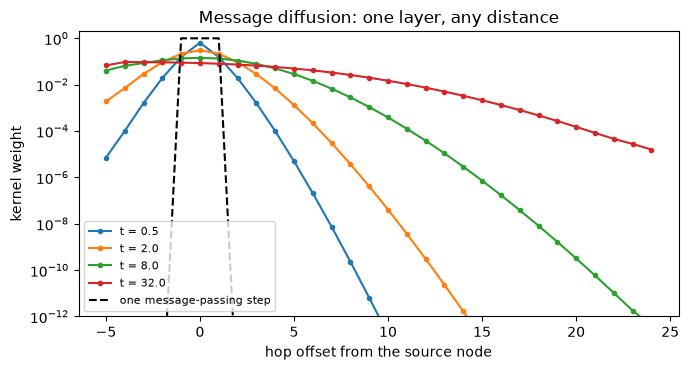

In [3]:
# =====================================================================
# Heat kernel weight vs hop distance on a path graph
# =====================================================================
n_path = 30
A_path = torch.zeros(n_path, n_path)
for u in range(n_path - 1):
    A_path[u, u + 1] = A_path[u + 1, u] = 1.0
dp = A_path.sum(1).pow(-0.5)
L_path = torch.eye(n_path) - dp[:, None] * A_path * dp[None, :]  # normalize="sym"

source = 5
fig, ax = plt.subplots(figsize=(7, 3.8))
for t in [0.5, 2.0, 8.0, 32.0]:
    kernel = torch.matrix_exp(-t * L_path)[source]
    ax.semilogy(
        np.arange(n_path) - source,
        kernel.clamp_min(1e-16).numpy(),
        marker=".",
        label=f"t = {t}",
    )
one_hop = (A_path[source] > 0).float()
ax.semilogy(
    np.arange(n_path) - source,
    (one_hop + (torch.arange(n_path) == source).float()).clamp_min(1e-16).numpy(),
    "k--",
    label="one message-passing step",
)
ax.set(
    xlabel="hop offset from the source node",
    ylabel="kernel weight",
    ylim=(1e-12, 2),
    title="Message diffusion: one layer, any distance",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

<a id="solvers"></a>
### 4.2 Taylor and Spectral Solvers

The repository evaluates the heat kernel in two ways (`solver` argument):
* **`"taylor"`** (Algorithm 1 of the paper): $e^{-t\mathcal{L}}X \approx \sum_{k=0}^{K} \frac{(-t\mathcal{L})^k}{k!}X$, with $K$ sparse message-passing steps. It is cheap and scalable, but a truncated series only works when $t\lambda_{\max}$ is moderate: the terms grow before they shrink.
* **`"spectral"`** (Algorithm 2): $\sum_i e^{-t\lambda_i}\boldsymbol{\varphi}_i\boldsymbol{\varphi}_i^{\top}X$, exact for any $t$, but it needs the Laplacian eigenvectors (all of them, or the top `num_eigs`).

The repository picks the Taylor degree automatically with `stable_taylor_degree(t)`, and caps a learned $t$ at what that degree can represent. The experiment below shows why: for each $t$, it measures the relative error of the truncated series on the path graph as $K$ grows.

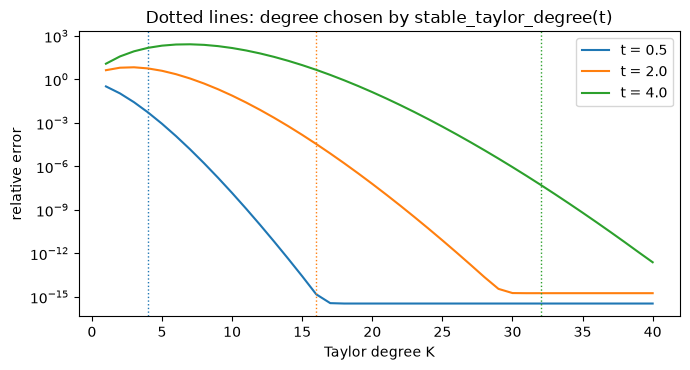

{0.5: 4, 1.0: 8, 2.0: 16, 4.0: 32}


In [4]:
# =====================================================================
# Taylor truncation error vs degree K, for several diffusion times
# =====================================================================
Xp = torch.randn(n_path, 4, dtype=torch.float64)
Lp = L_path.double()
fig, ax = plt.subplots(figsize=(7, 3.8))
for t in [0.5, 2.0, 4.0]:
    exact = torch.matrix_exp(-t * Lp) @ Xp
    term, approx, errs = Xp.clone(), Xp.clone(), []
    for k in range(1, 41):
        term = (-t / k) * (Lp @ term)
        approx = approx + term
        errs.append(((approx - exact).norm() / exact.norm()).item())
    (line,) = ax.semilogy(range(1, 41), errs, label=f"t = {t}")
    ax.axvline(stable_taylor_degree(t), color=line.get_color(), ls=":", lw=1)
ax.set(
    xlabel="Taylor degree K",
    ylabel="relative error",
    title="Dotted lines: degree chosen by stable_taylor_degree(t)",
)
ax.legend()
plt.tight_layout()
plt.show()
print({t: stable_taylor_degree(t) for t in [0.5, 1.0, 2.0, 4.0]})

<a id="5-dataset-and-models"></a>
# 5. Dataset Pipeline and Models

We use the same kind of heterophilic graph as notebooks 4 and 5: a two-class stochastic block model with 160 nodes and edge homophily around 0.15. Most edges cross classes, so a good bundle should give the two classes **opposite** frames, so that synchronizing a neighbour of the other class flips its features.

The BuNN layer (`BuNNConv`) performs, for $b$ parallel bundles of dimension $d = 2$:
1. **Embed:** predict the node frames $O_v$ from the current features with an MLP $\phi$. For $d = 2$ the repository uses a direct angle parameterization. The first half of the bundles are rotations and the rest reflections.
2. **Update:** $\mathbf{h}_v = O_v^{\top}\big(W\,O_v\mathbf{x}_v + \mathbf{b}\big)$, a linear map applied in the synchronized frame.
3. **Diffuse:** apply the heat kernel $e^{-t\mathcal{L}}$ in the synchronized frame, then desynchronize.
4. **Nonlinearity:** ELU, applied after the diffusion.

We train a BuNN with a fixed diffusion time $t = 1$ next to a first-order NSD with diagonal maps and a features-only MLP. The MLP tells us whether using the graph helps at all.

In [5]:
def random_splits(n: int, train: float = 0.4, val: float = 0.2, seed: int = SEED):
    """Disjoint boolean train/val/test masks over n nodes."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train, n_val = int(train * n), int(val * n)
    masks = [torch.zeros(n, dtype=torch.bool) for _ in range(3)]
    masks[0][perm[:n_train]] = True
    masks[1][perm[n_train : n_train + n_val]] = True
    masks[2][perm[n_train + n_val :]] = True
    return masks


# =====================================================================
# Heterophilic SBM and the two models
# =====================================================================
set_seed(SEED)
n, h, avg_degree = 160, 0.15, 6
half = n // 2
p_in, p_out = h * avg_degree / half, (1 - h) * avg_degree / half
edge_index = stochastic_blockmodel_graph([half, half], [[p_in, p_out], [p_out, p_in]])
y = torch.cat([torch.zeros(half), torch.ones(half)]).long()
x = torch.randn(n, 4)
x[:, 0] += 0.7 * (2 * y.float() - 1)
train_mask, val_mask, test_mask = random_splits(n)
data = Data(
    x=x,
    y=y,
    edge_index=edge_index,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
)
print(f"Edge homophily: {homophily(edge_index, y, method='edge'):.3f}")


def bunn_model(solver="taylor", learn_tau=False):
    return BuNNModel(
        4,
        2,
        bundle_dim=2,
        hidden_dim=8,
        num_bundles=2,
        num_layers=2,
        tau=1.0,
        learn_tau=learn_tau,
        solver=solver,
    )


def mlp_model():
    return nn.Sequential(nn.Linear(4, 16), nn.ELU(), nn.Linear(16, 2))


def nsd_model():
    return NSDModel(
        4, 2, stalk_dim=2, hidden_dim=8, num_layers=2, variant=NSDVariant.DIAGONAL
    )


demo = bunn_model()
layer0 = demo.layers[0]
print(
    f"BuNN layer: {type(layer0).__name__} | bundles = {layer0.num_bundles}, bundle_dim = {layer0.bundle_dim}, "
    f"channels per bundle = {layer0.in_channels}"
)
print(
    f"solver = {layer0.solver}, Taylor degree K = {layer0.max_degree}, learn_tau = {layer0.learn_tau}, "
    f"tau cap = {layer0.tau_cap}"
)

Edge homophily: 0.157
BuNN layer: BuNNConv | bundles = 2, bundle_dim = 2, channels per bundle = 8
solver = taylor, Taylor degree K = 8, learn_tau = False, tau cap = 1.0


<a id="6-training-pipeline"></a>
# 6. Training Pipeline

All models are trained with three seeds using masked cross-entropy and validation-based selection. BuNN uses a smaller learning rate (0.003), which trains it more reliably on this graph.

--- Test accuracy (3 seeds) ---
BuNN                 0.714 +/- 0.037
NSD                  0.812 +/- 0.046
MLP (features only)  0.693 +/- 0.007


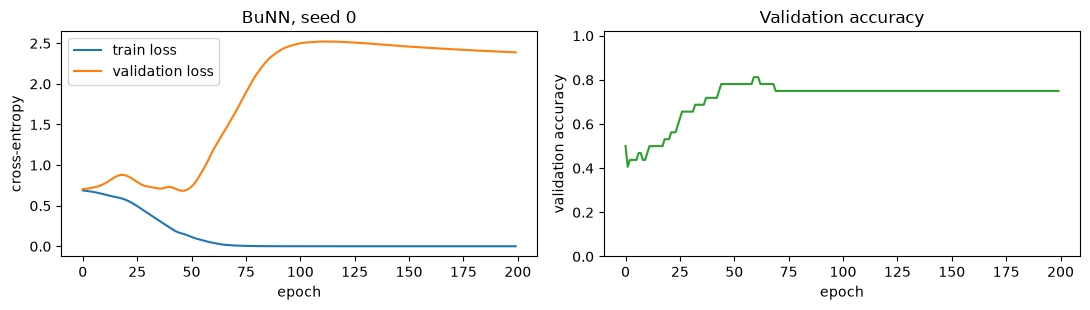

In [6]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# Masked training with validation-based model selection
# =====================================================================
def accuracy(logits: torch.Tensor, y: torch.Tensor, mask: torch.Tensor) -> float:
    return (logits[mask].argmax(-1) == y[mask]).float().mean().item()


def train_model(
    model, predict, data, epochs=150, lr=0.01, weight_decay=5e-4, extra_loss=None
):
    """Adam on masked cross-entropy; restores the state with the lowest validation loss.

    Args:
        model: the network to optimize.
        predict: zero-argument callable returning logits [N, C] for the whole graph.
        data: PyG Data with y, train_mask, val_mask, test_mask.
        epochs: number of full-batch optimization steps.
        lr: Adam learning rate.
        weight_decay: Adam L2 penalty.
        extra_loss: optional callable(epoch) -> scalar added to the loss (e.g. a KL term).

    Returns:
        (history, test_accuracy) where history holds one dict per epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_val, best_state = [], float("inf"), None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = predict()
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        if extra_loss is not None:
            loss = loss + extra_loss(epoch)
        assert torch.isfinite(loss), "non-finite training loss"
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = predict()
            val_loss = F.cross_entropy(
                val_logits[data.val_mask], data.y[data.val_mask]
            ).item()
        history.append(
            {
                "train_loss": loss.item(),
                "val_loss": val_loss,
                "val_acc": accuracy(val_logits, data.y, data.val_mask),
            }
        )
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())

    assert best_state is not None, "No finite validation score; check epochs and loss"
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(predict(), data.y, data.test_mask)
    return history, test_acc


def plot_history(history, title):
    """Training/validation curves of one run."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot([h["train_loss"] for h in history], label="train loss")
    axes[0].plot([h["val_loss"] for h in history], label="validation loss")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy", title=title)
    axes[0].legend()
    axes[1].plot([h["val_acc"] for h in history], color="tab:green")
    axes[1].set(
        xlabel="epoch",
        ylabel="validation accuracy",
        ylim=(0, 1.02),
        title="Validation accuracy",
    )
    plt.tight_layout()
    plt.show()


# =====================================================================
# Train BuNN and NSD
# =====================================================================
results, trained = {}, {}
setups = [
    ("BuNN", bunn_model, 0.003),
    ("NSD", nsd_model, 0.01),
    ("MLP (features only)", mlp_model, 0.01),
]
for name, factory, lr in setups:
    accs = []
    for seed in (0, 1, 2):
        set_seed(seed)
        model = factory()
        if name.startswith("MLP"):

            def predict(m=model):
                return m(data.x)
        else:

            def predict(m=model):
                return m(data.x, data.edge_index)

        history, acc = train_model(model, predict, data, epochs=200, lr=lr)
        accs.append(acc)
        if seed == 0:
            trained[name] = (model, history)
    results[name] = accs

print("--- Test accuracy (3 seeds) ---")
for name, accs in results.items():
    print(f"{name:<20} {np.mean(accs):.3f} +/- {np.std(accs):.3f}")
plot_history(trained["BuNN"][1], "BuNN, seed 0")

**Reading the table.** On this small heterophilic graph, BuNN is typically *less* accurate than NSD, and it may not beat the features-only MLP either. Two properties of the layer explain why, and they are worth knowing before using BuNN:
* **No separate skip connection.** Each layer replaces a node's features with their *diffused* version. The node's own features survive only through the diagonal of the heat kernel, which shrinks as $t$ grows. NSD, by contrast, keeps $\mathbf{x}$ and subtracts a diffusion term.
* **Diffusion mixes before the frames are right.** Until the frames learn to flip cross-class neighbours, heat diffusion averages a node with mostly *opposite-class* neighbours, which destroys the class signal (notebook 0, Section 12.2).

BuNN's strengths lie elsewhere: long-range interactions, where one layer of message diffusion replaces many layers of message passing, and larger graphs where tuned diffusion times and bundle counts matter. The paper's results use extensive hyperparameter search. The interpretation below asks what the model *did* learn here.

<a id="7-interpretation"></a>
# 7. Interpreting a Trained BuNN

<a id="learned-frames"></a>
### 7.1 Learned Node Frames

Each node's frame in each bundle is a $2 \times 2$ orthogonal matrix, so it is described by a single **angle** (plus whether it is a rotation or a reflection). We recompute the first layer's frames with its own map learner $\phi$, applied to the lifted features exactly as in `BuNNModel.forward`, and plot the angle of every node, coloured by class.

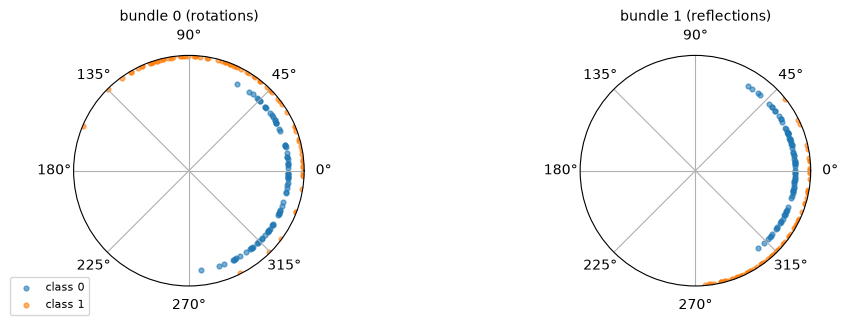

In [7]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Frames of the first layer, per bundle
# =====================================================================
bunn = trained["BuNN"][0].eval()
with torch.no_grad():
    h0 = bunn.encoder(data.x)  # BuNNModel.forward: encoder, no activation
    frames0 = bunn.layers[0].map_learner(h0, data.edge_index)  # [N, b, 2, 2]
angle = torch.atan2(
    frames0[..., 0, 1], frames0[..., 0, 0]
)  # rows [cos, sin] in the O(2) parameterization
det = torch.linalg.det(frames0)

fig, axes = plt.subplots(
    1, frames0.size(1), figsize=(11, 3.4), subplot_kw={"projection": "polar"}
)
for b, ax in enumerate(np.atleast_1d(axes)):
    for cls, colour in [(0, "tab:blue"), (1, "tab:orange")]:
        a = angle[y == cls, b].numpy()
        ax.scatter(
            a,
            np.full_like(a, 1.0 + 0.15 * cls),
            s=12,
            color=colour,
            alpha=0.6,
            label=f"class {cls}",
        )
    kind = "rotations" if det[:, b].mean() > 0 else "reflections"
    ax.set_title(f"bundle {b} ({kind})", fontsize=10)
    ax.set_yticks([])
np.atleast_1d(axes)[0].legend(
    loc="lower left", fontsize=8, bbox_to_anchor=(-0.3, -0.15)
)
plt.tight_layout()
plt.show()

<a id="relative-transports"></a>
### 7.2 Relative Transports

Absolute angles are arbitrary: rotating *every* frame by the same amount changes nothing (a global gauge). What matters is the **relative transport** $O_u^{\top}O_v$ across each edge, which is always a rotation by some angle $\Delta\theta_{uv}$. A transport of $0$ carries features over unchanged, and a transport of $\pi$ is $-I$, which flips them. On this heterophilic graph, a useful bundle should transport cross-class edges by angles near $\pi$ and same-class edges by angles near $0$.

bundle 0: mean |angle| same-class 0.81 rad | cross-class 1.31 rad
bundle 1: mean |angle| same-class 0.61 rad | cross-class 0.83 rad


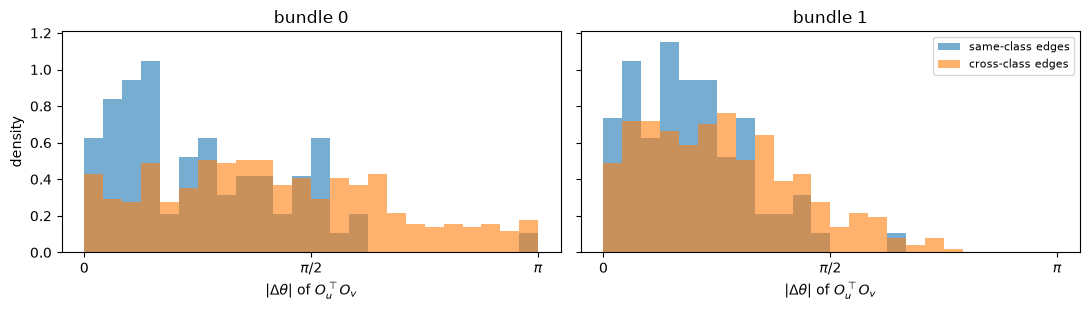

In [8]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Rotation angle of O_u^T O_v on same-class vs cross-class edges
# =====================================================================
src_i, dst_i = data.edge_index
transport = frames0[src_i].transpose(-1, -2) @ frames0[dst_i]  # [E, b, 2, 2]
rel_angle = torch.atan2(transport[..., 1, 0], transport[..., 0, 0]).abs()  # in [0, pi]
same = y[src_i] == y[dst_i]

fig, axes = plt.subplots(1, rel_angle.size(1), figsize=(11, 3.2), sharey=True)
for b, ax in enumerate(np.atleast_1d(axes)):
    bins = np.linspace(0, np.pi, 25)
    ax.hist(
        rel_angle[same, b].numpy(),
        bins=bins,
        alpha=0.6,
        density=True,
        label="same-class edges",
    )
    ax.hist(
        rel_angle[~same, b].numpy(),
        bins=bins,
        alpha=0.6,
        density=True,
        label="cross-class edges",
    )
    ax.set(title=f"bundle {b}", xlabel=r"$|\Delta\theta|$ of $O_u^\top O_v$")
    ax.set_xticks([0, np.pi / 2, np.pi], ["0", r"$\pi/2$", r"$\pi$"])
    print(
        f"bundle {b}: mean |angle| same-class {rel_angle[same, b].mean():.2f} rad | "
        f"cross-class {rel_angle[~same, b].mean():.2f} rad"
    )
np.atleast_1d(axes)[0].set_ylabel("density")
np.atleast_1d(axes)[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

If the cross-class histogram sits to the right of the same-class one, the model is moving towards the "flip across classes" geometry that NSD's theory predicts for heterophilic graphs, here with only one frame per node instead of one map per edge. On this toy the shift is **partial**: cross-class edges are rotated noticeably more than same-class edges (the polar plot shows the two classes drifting to different angles), but on average they stay well short of the ideal angle $\pi$. That is consistent with the accuracy table: the frames have started to separate the classes without fully undoing the heterophily. A bundle whose two histograms coincide is not using its geometry at all, and the classification must then come from the features and the update weights alone. Compare the two bundles: they can specialize differently.

<a id="diffusion-times"></a>
### 7.3 Diffusion Times and Solver Agreement

Every layer stores one diffusion time per bundle. Here they are fixed at $t = 1$. With `learn_tau=True` they become parameters, kept non-negative by a ReLU and, under the Taylor solver, **clamped** at the largest $t$ the truncation degree can represent (`tau_cap`). A learned value sitting exactly at the cap is pinned there and receives no gradient. To let it grow, raise `max_degree` or switch to the spectral solver.

Finally, we load the trained weights into a model that uses the **exact spectral** solver and compare the predictions, to check that the Taylor approximation did not distort the trained model.

In [9]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Learned diffusion times, and Taylor vs exact spectral predictions
# =====================================================================
for i, layer in enumerate(bunn.layers):
    tau = layer._scaled_tau(data.x).flatten()
    print(
        f"layer {i}: t per bundle = {np.round(tau.detach().numpy(), 3)} | Taylor degree K = {layer.max_degree} "
        f"| cap a learned t would have: {layer.tau_cap}"
    )

spectral = bunn_model(solver="spectral")
spectral.load_state_dict(bunn.state_dict())
spectral.eval()
with torch.no_grad():
    p_taylor = bunn(data.x, data.edge_index).softmax(-1)
    p_spectral = spectral(data.x, data.edge_index).softmax(-1)
print(f"\nmax |p_taylor - p_spectral| = {(p_taylor - p_spectral).abs().max():.2e}")
print(
    f"test accuracy: taylor {accuracy(p_taylor, y, test_mask):.3f} | spectral {accuracy(p_spectral, y, test_mask):.3f}"
)

layer 0: t per bundle = [1. 1.] | Taylor degree K = 8 | cap a learned t would have: 1.0
layer 1: t per bundle = [1. 1.] | Taylor degree K = 8 | cap a learned t would have: 1.0

max |p_taylor - p_spectral| = 6.39e-04
test accuracy: taylor 0.766 | spectral 0.766


<a id="8-exercises"></a>
# 8. Configuration, Reproducibility, and Exercises

**Using it on real data.** BuNN is the `BUNN` model type; its knobs are prefixed `bunn-`:

```bash
sheaf run --preset texas_bunn
sheaf run --preset chameleon_filtered_bunn --model.bunn-tau 10 --model.bunn-solver spectral --model.bunn-num-eigs 128
sheaf run --preset texas_bunn --model.bunn-learn-tau --model.bunn-num-bundles 4
```

Record the solver, the diffusion time (and whether it was learned), the number of bundles, the Taylor degree or the number of eigenpairs, and the seed. Note that the spectral solver needs an eigendecomposition per graph, which the model caches.

**Key takeaways**
* A flat bundle assigns a frame per node; transports are relative frames, so the bundle Laplacian is "synchronize, graph Laplacian, desynchronize".
* The heat kernel lets one layer reach any distance, with the diffusion time as the receptive-field knob (message diffusion).
* Flat bundles keep the graph's spectrum, but their diffusion limit is "consistent up to frames" rather than "all equal", which is what keeps classes apart.
* A trained BuNN is readable: its frames, the relative transports they induce, and its diffusion times all come straight from the parameters.

### Hands-on Exercises
1. **Diffusion time.** Fix `tau` at 0.1, 1, and 10 (`learn_tau=False`). How do accuracy and the relative-transport histograms change?
2. **Bundles.** Train with `num_bundles=1` (a single rotation bundle) and `num_bundles=4`. Do some bundles specialize in same-class edges and others in cross-class edges?
3. **Holonomy.** Flat bundles cannot represent holonomy. Construct a small graph with a cycle where the "right" transport around the cycle is not the identity (e.g. an odd cycle with alternating labels). What does BuNN do there, and how does it compare with orthogonal NSD?
4. **Solvers.** Train directly with `solver="spectral"` and a large `tau`, then try the same `tau` with the Taylor solver. What does the model constructor tell you, and why?